# Assignment 1 – Model: single-storey two-zone office building (Chur)

**Team:** _Valerio Paganini_

Intermediate submission of the project (course *dm4bem*, Ch. Ghiaus). The figure contains the plan and section of the
building, the hypotheses, the types of walls, windows and door, the thermal circuit with the numbering of the nodes
and branches, and the tables of conductances, capacities, of the incidence matrix (row by row) and of the inputs.
This notebook writes the model in Python: the incidence matrix $A$, the conductance matrix $G$, the capacity
matrix $C$ and the vectors of pointers $b$, $f$ and $y$.

![Assignment 1: plan, section, hypotheses, thermal circuit and tables](figures/Assignment1_Model.drawio.svg)

> Figure 1. Assignment 1 on one page (draw.io file; open it in [diagrams.net](https://app.diagrams.net) to zoom).


In [1]:
import numpy as np
import pandas as pd
import dm4bem

## 1 Building and zones

Single-storey office building (SIA 2024 room type 3.01) in Chur above an unheated basement. The plan of
$30 \times 15$ m is divided along the east–west axis into zone 1 (south half) and zone 2 (north half), each
$30 \times 7.5$ m. The zones are separated by an uninsulated concrete wall with one closed door.

Areas of roof, floor and zones from the outer plan dimensions; façade areas = length × storey height 3.40 m
(assumption); air volume with the clear height 3.00 m. Window band on every façade with 60 % of the façade area.

In [2]:
# geometry
L, B = 30.0, 15.0           # m, plan (east-west × north-south)
H, H_c = 3.40, 3.00         # m, storey height (façade areas), clear height (air volume)
wwr = 0.60                  # window area / façade area

S_fac = {'long': L * H,     # façade S (zone 1) or N (zone 2)
         'short': B / 2 * H}            # half façade E or W of one zone
S_win = {o: wwr * S for o, S in S_fac.items()}
S_wall = {o: (1 - wwr) * S for o, S in S_fac.items()}
S_plan = L * B / 2                      # roof = floor of one zone
V_air = S_plan * H_c                    # air volume of one zone
door = {'b': 1.00, 'h': 2.10, 'w': 0.04, 'lambda': 0.13}     # solid timber door, closed (assumption)
S_door = door['b'] * door['h']
S_iw = L * H_c - S_door                 # interior wall without the door

pd.DataFrame({'gross': S_fac, 'window': S_win, 'opaque': S_wall}).round(1)

,gross,window,opaque
long,102.0,61.2,40.8
short,25.5,15.3,10.2


## 2 Hypotheses for the boundary conditions

1. **Building and zones**: single-storey office (SIA 2024 room type 3.01) in Chur, plan $30 \times 15$ m above
   an unheated basement; zone 1 = south half, zone 2 = north half (225 m² each), separated by an interior wall
   along the E–W axis. Roof, floor and zone areas from the outer plan dimensions, façade areas = length × storey
   height 3.40 m (assumption), air volume with the clear height 3.00 m.
2. **Conduction** one-dimensional, constant material properties, thermal bridges neglected, window frames
   included in $U_w$.
3. **Air** well mixed in each zone: one air node ($\theta_{71}$, $\theta_{144}$) with $C = \rho c V$.
4. **Outdoor**: temperature source $T_o$ (weather file Chur TMYx 2004–2018) on walls, windows, roof and
   ventilation; $h_o = 25$ W/(m²·K) includes the long-wave exchange with sky and surroundings.
5. **Basement** (unheated) as independent temperature source $T_{bsmt} = 20 °C - b\,(20 °C - T_{o,24h})$,
   $b = 0.7$ (assumption); surface coefficient on the basement side $1/R_{si,down} = 5.9$ W/(m²·K).
6. **Indoor convection** only on the convection branches: $h_c = 2.5$ W/(m²·K) on vertical surfaces
   (EN ISO 6946), 3.0 W/(m²·K) on ceiling and floor (assumption). The door has no long-wave branch and uses
   $R_{si} = 0.13$ m²·K/W (convection + long-wave) on both sides.
7. **Indoor long-wave radiation** linearised at $\bar T = 293$ K with the radiosity method of 03CubicBuilding.
   With the view factors $F_{ij} = S_j/S_T$ the network is a star ($\theta_{72}$, $\theta_{145}$) with
   $G_i = 4\sigma \bar T^3 \varepsilon_i S_i$; $\varepsilon = 0.85$ opaque, 0.90 glass. Surfaces in the same
   plane are not excluded; the summation rule is not satisfied ($\sum_{j \ne i} F_{ij} = 1 - S_i/S_T$), accepted
   as a simplification.
8. **Solar radiation**: $\Phi_o = \alpha S E$ on outer surfaces ($\alpha$ = 0.5 façade, 0.6 roof, assumption;
   none on the floor), $\Phi_a$ absorbed in the glass, transmitted radiation distributed over the inner surfaces
   as $\Phi_i$; external blinds ($g_{tot} = 0.10$, SIA 180) reduce the transmitted part.
9. **Internal gains**: occupants, equipment and lighting with their own SIA 2024 profiles, convective; one input
   per air node $f = \dot Q_{occ} + \dot Q_{equip} + \dot Q_{light}$.
10. **Ventilation** per zone: supply/exhaust with heat recovery $\eta = 0.75$ (assumption) plus infiltration as one
   advection branch from $T_o$: $G_v = \rho c\,[(1-\eta)\dot V_{mech} + \dot V_{inf}]$ (SIA 2024:
   29 m³/(h·P), 14 m²/P, 0.15 m³/(h·m²)).
11. **Coupling of the zones**: concrete interior wall (convection, conduction, long-wave on both sides) and the
    closed door ($U \cdot S$). No air exchange between the zones (assumption: door closed, balanced ventilation in
    both zones).
12. **HVAC**: one P-controller per zone, $q_{HVAC} = K_p (T_{sp} - \theta_a)$, set-point $T_{sp}$ as temperature
    source (21 °C heating / 26 °C cooling during occupancy, SIA 2024; 18 / 28 °C otherwise, assumption),
    $K_p = 10^5$ W/K (assumption); $K_p \to 0$ gives free running. $T_{sp}$ and $K_p$ are switched in time
    (dead band).
13. **Capacities** only at the mesh centres of insulation (2 meshes) and concrete (4 meshes), in the glass (80 % of
    the window area, frame neglected) and in the air.
14. **Floor above the basement**: mineral wool 0.14 m and concrete 0.30 m in meshes; the resistances of EPS 0.04 m and
    screed 0.08 m are added to the last half mesh of the concrete, their capacity is neglected (assumption).

## 3 Types of walls, windows and door

Layers from outside to inside; λ in W/(m·K), ρ in kg/m³, c in J/(kg·K) (design values, assumption).

In [3]:
mat = pd.DataFrame({'mineral_wool': [0.035, 30, 1030],
                    'PUR': [0.025, 30, 1400],
                    'concrete': [2.3, 2400, 880],
                    'EPS': [0.035, 20, 1450],
                    'screed': [1.4, 2200, 1000],
                    'glass': [1.0, 2500, 750]},
                   index=['lambda', 'rho', 'c']).T

wall = [('mineral_wool', 0.20), ('concrete', 0.20)]          # external wall, insulated outside
roof = [('PUR', 0.16), ('concrete', 0.28)]                   # roof, insulated outside
floor = [('mineral_wool', 0.14), ('concrete', 0.30)]         # above the unheated basement (meshed layers)
floor_top = [('EPS', 0.04), ('screed', 0.08)]                # only their resistance (hypothesis 14)
w_iw = 0.25                                                  # interior wall, concrete, no insulation

U_w, frame, w_glass, eps_g = 0.90, 0.20, 3 * 0.004, 0.90     # triple glazing, glass 3 × 4 mm
R_si, R_se = 0.13, 0.04                                      # m²·K/W (EN ISO 6946)
R_g = 1 / U_w - R_se - R_si                                  # glazing without the surface resistances
mat

,lambda,rho,c
mineral_wool,0.035,30.0,1030.0
PUR,0.025,30.0,1400.0
concrete,2.300,2400.0,880.0
EPS,0.035,20.0,1450.0
screed,1.400,2200.0,1000.0
glass,1.000,2500.0,750.0


## 4 Thermal circuit and 5 numbering

The circuit is drawn in Figure 1 (left). Each zone has 73 nodes and 89 branches, in this order: external wall,
window (orientation 1, 2, 3), roof, floor, ventilation, P-controller; then the air node and the long-wave star node.
Zone 2 has the numbers of zone 1 + 73 (nodes) and + 89 (branches). The interior wall (θ146–θ154, q178–q189) and the
door (q190) couple the two zones.

| Element | Nodes | Branches |
|---|---|---|
| opaque element | outer surface, 2 insulation meshes, 4 concrete meshes, inner surface (13) | outer surface, 4 + 8 half meshes, convection, long-wave (15) |
| window | glass, inner glass surface (2) | outdoor surface + ½ glass, ½ glass, convection, long-wave (4) |
| ventilation, P-controller | – | 1 each, from a temperature source to the air node |

## 6 Conductances and 7 capacities

- conduction: a layer cut into $n$ meshes gives $2n$ branches of $2n\lambda S/w$ each;
- convection: $hS$; long-wave: $4\sigma \bar T^3 \varepsilon S$; advection: $\rho c \dot V$; P-controller: $K_p$;
- capacity of a mesh: $\rho c w S / n$; air: $\rho c V$.

In [4]:
h_o, h_cw, h_cs, h_bsmt = 25.0, 2.5, 3.0, 1 / 0.17        # W/(m²·K): outdoor, indoor vertical, ceiling/floor, basement
sigma, T_m, eps = 5.67e-8, 293.0, 0.85                    # long-wave: σ, mean temperature, emissivity opaque
h_r = 4 * sigma * T_m**3                                  # W/(m²·K) per unit emissivity
rho_c_air = 1.2 * 1000                                    # J/(m³·K)

V_mech = S_plan / 14 * 29                                 # m³/h, SIA 2024: 14 m²/P, 29 m³/(h·P)
V_inf = 0.15 * S_plan                                     # m³/h
eta = 0.75                                                # heat recovery
G_v = rho_c_air / 3600 * ((1 - eta) * V_mech + V_inf)     # W/K, ventilation of one zone
K_p = 1e5                                                 # W/K, P-controller

print(f'h_r = {h_r:.3f} W/(m²·K), R_g = {R_g:.3f} m²·K/W, G_v = {G_v:.2f} W/K')

h_r = 5.705 W/(m²·K), R_g = 0.941 m²·K/W, G_v = 50.09 W/K


The functions below add the branches and capacities of each element **in the order of the numbering in
Figure 1**. A branch is stored as (from node, to node); `None` as start node means that the branch starts at a
temperature source.

In [5]:
branches = []          # (from node or None, to node, G in W/K, temperature source or None)
cap = {}               # node -> capacity in J/K
flow = {}              # node -> flow-rate source(s)


def lam(m):
    return mat.loc[m, 'lambda']


def rc(m):
    return mat.loc[m, 'rho'] * mat.loc[m, 'c']


def branch(frm, to, G, src=None):
    branches.append((frm, to, G, src))


def opaque(n, S, layers, h_out, h_in, air, rm, src='T_o', R_top=0.0, sun='Φo'):
    """Outer surface n, insulation (2 meshes), concrete (4 meshes), inner surface n + 12."""
    (m1, w1), (m2, w2) = layers
    branch(None, n, h_out * S, src)                            # outer surface
    for k in range(4):                                         # insulation: 4 half meshes
        branch(n + k, n + k + 1, 4 * lam(m1) * S / w1)
    for k in range(8):                                         # concrete: 8 half meshes
        G = 8 * lam(m2) * S / w2
        if k == 7 and R_top:                                   # last half mesh + EPS + screed (floor)
            G = S / (w2 / (8 * lam(m2)) + R_top)
        branch(n + 4 + k, n + 5 + k, G)
    branch(n + 12, air, h_in * S)                              # convection indoor
    branch(n + 12, rm, h_r * eps * S)                          # long-wave to the star node
    for i in (1, 3):                                           # mesh centres of the insulation
        cap[n + i] = rc(m1) * w1 * S / 2
    for i in (5, 7, 9, 11):                                    # mesh centres of the concrete
        cap[n + i] = rc(m2) * w2 * S / 4
    if sun:
        flow.setdefault(n, []).append(sun)                     # solar radiation on the outer surface
    flow.setdefault(n + 12, []).append('Φi')                   # transmitted solar radiation inside


def window(n, S, air, rm):
    """Glass node n, inner glass surface n + 1."""
    branch(None, n, S / (1 / h_o + R_g / 2), 'T_o')            # outdoor surface + 1/2 glass
    branch(n, n + 1, 2 * S / R_g)                              # 1/2 glass
    branch(n + 1, air, h_cw * S)                               # convection indoor
    branch(n + 1, rm, h_r * eps_g * S)                         # long-wave to the star node
    cap[n] = rc('glass') * w_glass * (1 - frame) * S           # glass only (frame neglected)
    flow.setdefault(n, []).append('Φa')                        # solar radiation absorbed in the glass


def zone(n0, z):
    """Zone z with first node n0: 3 walls with windows, roof, floor, ventilation, P-controller."""
    air, rm = n0 + 71, n0 + 72
    n = n0
    for o in ('long', 'short', 'short'):                                                   # S/N, E, W
        opaque(n, S_wall[o], wall, h_o, h_cw, air, rm)
        n += 13
        window(n, S_win[o], air, rm)
        n += 2
    opaque(n, S_plan, roof, h_o, h_cs, air, rm)                                            # roof
    n += 13
    R_top = sum(w / lam(m) for m, w in floor_top)
    opaque(n, S_plan, floor, h_bsmt, h_cs, air, rm, src='T_bsmt', R_top=R_top, sun=None)   # floor
    branch(None, air, G_v, 'T_o')                                                          # ventilation (advection)
    branch(None, air, K_p, f'T_sp,{z}')                                                    # P-controller
    cap[air] = rho_c_air * V_air
    flow.setdefault(air, []).append('Q̇occ + Q̇equip + Q̇light')
    return air, rm


air1, rm1 = zone(0, 1)                                                    # zone 1, south: θ0 ... θ72
air2, rm2 = zone(73, 2)                                                   # zone 2, north: θ73 ... θ145

n = 146                                                                   # interior wall θ146 ... θ154, concrete 4 meshes
branch(air1, n, h_cw * S_iw)                                              # convection zone 1 side
for k in range(8):
    branch(n + k, n + k + 1, 8 * lam('concrete') * S_iw / w_iw)
branch(n + 8, air2, h_cw * S_iw)                                          # convection zone 2 side
branch(n, rm1, h_r * eps * S_iw)                                          # long-wave zone 1
branch(n + 8, rm2, h_r * eps * S_iw)                                      # long-wave zone 2
for i in (1, 3, 5, 7):
    cap[n + i] = rc('concrete') * w_iw * S_iw / 4
flow.setdefault(n, []).append('Φi')
flow.setdefault(n + 8, []).append('Φi')
branch(air1, air2, S_door / (R_si + door['w'] / door['lambda'] + R_si))   # closed door

nq, nθ = len(branches), 155
print(f'{nθ} nodes, {nq} branches, {len(cap)} capacities, {len(flow)} nodes with flow-rate sources')

155 nodes, 191 branches, 72 capacities, 28 nodes with flow-rate sources


## 8 Incidence matrix $A$, conductance matrix $G$ and capacity matrix $C$

System of differential-algebraic equations (DAE):

$$C \dot \theta = -A^T G A \theta + A^T G b + f, \qquad q = G(-A\theta + b)$$

Row $k$ of $A$: $-1$ in the column of the node where the flow $q_k$ leaves, $+1$ where it enters; a branch that
starts at a temperature source has only the $+1$.

In [6]:
A = np.zeros([nq, nθ])                              # incidence matrix, branches × nodes
for k, (frm, to, _, _) in enumerate(branches):
    if frm is not None:
        A[k, frm] = -1                              # q_k leaves node frm
    A[k, to] = 1                                    # q_k enters node to

G = np.diag([g for _, _, g, _ in branches])         # conductance matrix, W/K
C = np.diag([cap.get(i, 0.0) for i in range(nθ)])   # capacity matrix, J/K

q_names = [f'q{k}' for k in range(nq)]
θ_names = [f'θ{i}' for i in range(nθ)]
print(f'A: {A.shape}, G: {G.shape}, C: {C.shape}')

A: (191, 155), G: (191, 191), C: (155, 155)


The matrix $A$ is too large to print. Its rows for the first element, the south wall of zone 1
(branches $q_0 \dots q_{14}$), are not zero only in the columns of the wall nodes $\theta_0 \dots \theta_{12}$, of the air node
$\theta_{71}$ and of the star node $\theta_{72}$. The same block repeats for every opaque element at its own numbers.

In [7]:
cols = list(range(13)) + [air1, rm1]
pd.DataFrame(A[:15][:, cols].astype(int), index=q_names[:15], columns=[θ_names[i] for i in cols])

,θ0,θ1,θ2,θ3,θ4,θ5,θ6,θ7,θ8,θ9,θ10,θ11,θ12,θ71,θ72
q0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
q1,-1,1,0,0,0,0,0,0,0,0,0,0,0,0,0
q2,0,-1,1,0,0,0,0,0,0,0,0,0,0,0,0
q3,0,0,-1,1,0,0,0,0,0,0,0,0,0,0,0
q4,0,0,0,-1,1,0,0,0,0,0,0,0,0,0,0
q5,0,0,0,0,-1,1,0,0,0,0,0,0,0,0,0
q6,0,0,0,0,0,-1,1,0,0,0,0,0,0,0,0
q7,0,0,0,0,0,0,-1,1,0,0,0,0,0,0,0
q8,0,0,0,0,0,0,0,-1,1,0,0,0,0,0,0
q9,0,0,0,0,0,0,0,0,-1,1,0,0,0,0,0


Picture of the whole matrix $A$: red $+1$ (the flow enters the node), blue $-1$ (the flow leaves the node).
The two zones are the two diagonal blocks; the columns of the air nodes ($\theta_{71}$, $\theta_{144}$) and of the
star nodes ($\theta_{72}$, $\theta_{145}$) collect the convection and long-wave branches of each zone.

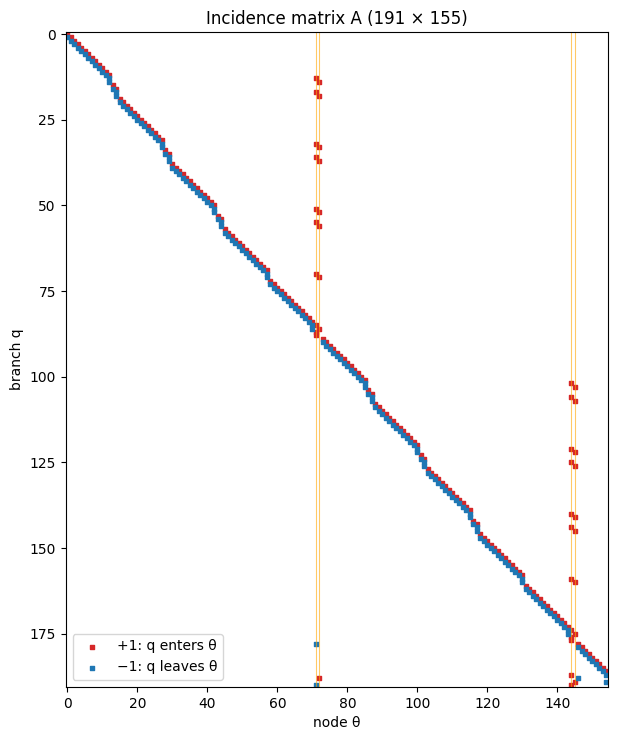

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 8.5))
r, c = np.nonzero(A > 0)
ax.scatter(c, r, s=6, marker='s', color='tab:red', label='+1: q enters θ')
r, c = np.nonzero(A < 0)
ax.scatter(c, r, s=6, marker='s', color='tab:blue', label='−1: q leaves θ')
for x in (air1, rm1, air2, rm2):
    ax.axvline(x, color='orange', lw=0.8, alpha=0.6)
ax.set(xlim=(-0.5, nθ - 0.5), ylim=(nq - 0.5, -0.5), xlabel='node θ', ylabel='branch q',
       title=f'Incidence matrix A ({nq} × {nθ})')
ax.legend(loc='lower left')
plt.show()

$G$ and $C$ are diagonal. Diagonal of $G$ for the south wall of zone 1 and all non-zero capacities:

In [9]:
pd.DataFrame({'G W/K': np.diag(G)[:15].round(2)}, index=q_names[:15]).T

,q0,q1,q2,q3,q4,q5,q6,q7,q8,q9,q10,q11,q12,q13,q14
G W/K,1020.0,28.56,28.56,28.56,28.56,3753.6,3753.6,3753.6,3753.6,3753.6,3753.6,3753.6,3753.6,102.0,197.84


In [10]:
c_nz = np.flatnonzero(np.diag(C))
with pd.option_context('display.max_rows', 80):
    display(pd.DataFrame({'C J/K': np.diag(C)[c_nz].round(0)}, index=[θ_names[i] for i in c_nz]))

,C J/K
θ1,126072.0
θ3,126072.0
θ5,4308480.0
θ7,4308480.0
θ9,4308480.0
θ11,4308480.0
θ13,1101600.0
θ16,31518.0
θ18,31518.0
θ20,1077120.0


## 9 Inputs and outputs: vectors of pointers $b$, $f$ and $y$

$b_k = 1$ for the branches with a temperature source, $f_i = 1$ for the nodes with a flow-rate source,
$y_i = 1$ for the output temperatures (air of both zones).

In [11]:
b = np.zeros(nq)                                           # temperature sources (branches)
b[[k for k, (_, _, _, s) in enumerate(branches) if s]] = 1

f = np.zeros(nθ)                                           # flow-rate sources (nodes)
f[sorted(flow)] = 1

y = np.zeros(nθ)                                           # outputs: air temperatures
y[[air1, air2]] = 1

sources = pd.Series({k: s for k, (_, _, _, s) in enumerate(branches) if s})
with pd.option_context('display.max_colwidth', None):     # show the lists in full
    display(pd.DataFrame({'temperature source': sources.unique(),
                          'branches with b = 1': [', '.join(f'q{k}' for k in sources.index[sources == s])
                                                  for s in sources.unique()]}))

,temperature source,branches with b = 1
0,T_o,"q0, q15, q19, q34, q38, q53, q57, q87, q89, q104, q108, q123, q127, q142, q146, q176"
1,T_bsmt,"q72, q161"
2,"T_sp,1",q88
3,"T_sp,2",q177


In [12]:
kinds = {'Φo': 'solar on outer surface', 'Φi': 'transmitted solar on inner surface',
         'Φa': 'solar absorbed in the glass', 'Q̇occ + Q̇equip + Q̇light': 'internal gains'}
with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame({'flow-rate source': list(kinds.values()),
                          'nodes with f = 1': [', '.join(f'θ{i}' for i in sorted(flow) if k in flow[i])
                                               for k in kinds]}))

,flow-rate source,nodes with f = 1
0,solar on outer surface,"θ0, θ15, θ30, θ45, θ73, θ88, θ103, θ118"
1,transmitted solar on inner surface,"θ12, θ27, θ42, θ57, θ70, θ85, θ100, θ115, θ130, θ143, θ146, θ154"
2,solar absorbed in the glass,"θ13, θ28, θ43, θ86, θ101, θ116"
3,internal gains,"θ71, θ144"


In [13]:
print('y = 1 at', ', '.join(θ_names[i] for i in np.flatnonzero(y)), '(air temperatures of zone 1 and zone 2)')

y = 1 at θ71, θ144 (air temperatures of zone 1 and zone 2)


## Checks

1. All temperature sources equal to 1 and no flow-rate sources: every node must have $\theta = 1$ (signs of $A$).
2. Outdoor and basement at 0 °C, set-points 20 °C: heat load of the building (steady state).
3. The state-space model from `dm4bem.tc2ss` (number of states = number of capacities).

In [14]:
K = A.T @ G @ A
θ = np.linalg.solve(K, A.T @ G @ b)
print(f'1) θ min / max = {θ.min():.12f} / {θ.max():.12f}')

T_sp = np.array([20.0 if s and s.startswith('T_sp') else 0.0 for _, _, _, s in branches])
θ = np.linalg.solve(K, A.T @ G @ T_sp)
q = np.diag(G) * (-A @ θ + T_sp)
k_sp = [k for k, (_, _, _, s) in enumerate(branches) if s and s.startswith('T_sp')]
print(f'2) θ_air = {θ[air1]:.2f} / {θ[air2]:.2f} °C, q_HVAC = {q[k_sp[0]]:.0f} + {q[k_sp[1]]:.0f} W')

As, Bs, Cs, Ds = dm4bem.tc2ss(A, G, C, b, f, y)
print(f'3) state space: {As.shape[0]} states, {Bs.shape[1]} inputs, {Cs.shape[0]} outputs')

1) θ min / max = 1.000000000000 / 1.000000000000


2) θ_air = 19.96 / 19.96 °C, q_HVAC = 4143 + 4143 W


3) state space: 72 states, 48 inputs, 2 outputs
